# 03. Transformation : la table d'analyse du risque de décrochage

Sentinelle Scolaire, défi 1.

Cette étape réunit les tables nettoyées en une **table d'analyse unique** : une ligne par province (45, ancien découpage) et par année scolaire t, de 2016-2017 à 2024-2025.

- **La cible** est l'abandon apparent du cycle CP1-CM1 entre t et t+1, recalculé à partir des effectifs.
- **Quand les effectifs varient de plus de 30 %** entre t et t+1, la ligne est classée en *rupture de scolarisation* : fermetures ou réouvertures massives d'écoles. La cible y est laissée vide, et ces cas sont traités à part.
- **Les variables explicatives** ne portent que sur l'année t ou les précédentes : le modèle ne voit jamais l'avenir.
- **Les valeurs absentes des sources restent vides.**

Une seconde table, mensuelle, suit les déplacés par province entre deux annuaires (alerte avant l'annuaire).

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
from sentinelle.depots import exporter_transformation
from sentinelle.transformation import executer_transformation

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})

## 1. Construction et contrôles

In [2]:
resultat = executer_transformation()
panel = resultat["panel_province_annee"]
resultat["controles_transformation"]

,controle,conforme,detail
0,une_ligne_par_province_et_annee,True,"405 lignes = 45 provinces × 9 années, sans doublon"
1,cible_renseignee,True,"abandon observé : 321, à prévoir : 45, rupture de scolarisation : 39"
2,aucune_variable_explicative_venant_du_futur,True,les variables de t+1 servent seulement à définir la cible
3,toutes_les_variables_decrites,True,45 variables décrites
4,jointure_carte_2025,True,les 45 provinces du panel couvrent les 47 provinces de 2025
5,panel_mensuel_sans_doublon,True,"1764 lignes, 44 mois (2019-01 à 2023-03)"
6,panel_region_une_ligne_par_region_et_annee,True,140 lignes = 13 régions et le pays × 10 années
7,somme_des_regions_egale_national,True,écart maximal 0 élève sur 10 années
8,public_plus_prive_egal_total_national,True,écart maximal 0 élève
9,taux_achevement_national_2024_2025,True,"51.6 % en 2024-2025, valeur citée dans la note d'intention"


## 2. La cible

In [3]:
pd.crosstab(panel["annee_scolaire"], panel["statut_cible"])

statut_cible,abandon observé,rupture de scolarisation,à prévoir
annee_scolaire,,,
2016-2017,45,0,0
2017-2018,41,4,0
2018-2019,42,3,0
2019-2020,43,2,0
2020-2021,39,6,0
2021-2022,34,11,0
2022-2023,35,10,0
2023-2024,42,3,0
2024-2025,0,0,45


In [4]:
observe = panel[panel["statut_cible"] == "abandon observé"]
resume = observe.groupby("annee_scolaire")["abandon_suivant"].describe()[["count", "25%", "50%", "75%"]].round(1)
resume

,count,25%,50%,75%
annee_scolaire,,,,
2016-2017,45.0,5.0,6.2,7.4
2017-2018,41.0,5.8,7.4,9.9
2018-2019,42.0,6.2,8.2,17.4
2019-2020,43.0,5.5,8.4,10.8
2020-2021,39.0,8.4,10.1,16.6
2021-2022,34.0,10.1,14.0,21.8
2022-2023,35.0,4.7,7.6,11.4
2023-2024,42.0,5.8,8.2,12.4


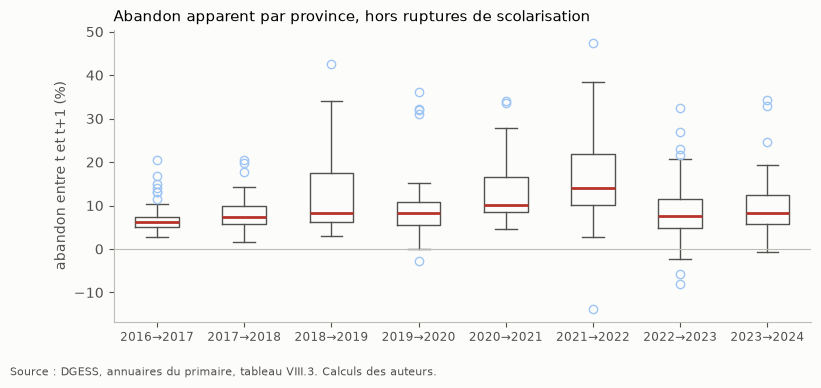

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
annees = sorted(observe["annee_scolaire"].unique())
ax.boxplot([observe.loc[observe["annee_scolaire"] == a, "abandon_suivant"] for a in annees], widths=0.5,
           medianprops={"color": "#b8342a", "linewidth": 2}, boxprops={"color": "#52514e"},
           whiskerprops={"color": "#52514e"}, capprops={"color": "#52514e"},
           flierprops={"markeredgecolor": "#9ec5f4"})
ax.set_xticks(range(1, len(annees) + 1), [f"{a[:4]}→{int(a[:4]) + 1}" for a in annees], fontsize=8.5)
ax.set_ylabel("abandon entre t et t+1 (%)")
ax.axhline(0, color="#bdbcb6", linewidth=0.8)
ax.set_title("Abandon apparent par province, hors ruptures de scolarisation", loc="left", fontsize=11)
fig.text(0.01, -0.03, "Source : DGESS, annuaires du primaire, tableau VIII.3. Calculs des auteurs.", fontsize=8, color="#52514e")
plt.show()

## 3. Les variables explicatives

Le dictionnaire donne, pour chaque variable, son rôle, sa source, sa part de valeurs manquantes et les années qu'elle couvre.

In [6]:
dico = resultat["dictionnaire_variables_modele"]
dico[dico["role"] == "explicative"][["variable", "description", "source", "part_manquante", "premiere_annee", "derniere_annee"]]

,variable,description,source,part_manquante,premiere_annee,derniere_annee
7,abandon_precedent,"Abandon entre t-1 et t, en %","DGESS, tableau VIII.3",0.000,2016-2017,2024-2025
8,redoublement_precedent,"Redoublement entre t-1 et t, en %","DGESS, tableau VIII.3",0.000,2016-2017,2024-2025
9,promotion_precedente,"Promotion entre t-1 et t, en %","DGESS, tableau VIII.3",0.000,2016-2017,2024-2025
10,effectif,Effectif total du primaire en t,"DGESS, tableau VIII.3",0.000,2016-2017,2024-2025
11,part_filles,Part des filles dans l'effectif ; vide quand la répartition publiée est invraisemblable,"DGESS, tableau VIII.3",0.106,2016-2017,2024-2025
12,part_cp1,Part du CP1 dans l'effectif,"DGESS, tableau VIII.3",0.002,2016-2017,2024-2025
13,rapport_cm2_cp1,Effectif du CM2 rapporté à celui du CP1,"DGESS, tableau VIII.3",0.002,2016-2017,2024-2025
14,effectif_precedent,Effectif total en t-1,"DGESS, tableau VIII.3",0.000,2016-2017,2024-2025
16,evolution_effectifs,Évolution des effectifs entre t-1 et t,"DGESS, tableau VIII.3",0.000,2016-2017,2024-2025
18,choc_effectifs,Vrai si les effectifs ont varié de plus de 30% entre t-1 et t,"DGESS, tableau VIII.3",0.000,2016-2017,2024-2025


### Premières relations avec la cible

Corrélation de rang (Spearman) entre chaque variable explicative et l'abandon de l'année suivante, sur les lignes où les deux sont connues. Ce sont des associations, pas des effets : elles orientent le choix des variables du modèle.

In [7]:
explicatives = dico.loc[dico["role"] == "explicative", "variable"]
numeriques = [v for v in explicatives if pd.api.types.is_numeric_dtype(panel[v]) and panel[v].dtype != bool]
lignes = []
for variable in numeriques:
    paire = observe[[variable, "abandon_suivant"]].dropna()
    if len(paire) >= 30:
        lignes.append({"variable": variable, "lignes": len(paire),
                       "correlation_rang": round(paire[variable].corr(paire["abandon_suivant"], method="spearman"), 2)})
pd.DataFrame(lignes).sort_values("correlation_rang", key=abs, ascending=False)

,variable,lignes,correlation_rang
6,rapport_cm2_cp1,321,-0.42
5,part_cp1,321,0.40
0,abandon_precedent,321,0.38
26,taux_prescolarisation_province,42,-0.38
2,promotion_precedente,321,-0.32
18,taux_achevement_region,321,-0.32
13,deplaces_pour_100_eleves,149,0.31
19,ips_tbs_region,321,-0.30
27,grande_section_province,42,-0.30
12,deplaces,149,0.27


### Le contexte régional de la base principale

Chaque province reçoit les indicateurs de sa région pour l'année t : taux bruts d'admission et de scolarisation, taux d'achèvement, parité, préscolaire, part des écoles privées. La réussite au CEP est celle de la session qui clôt t-1 : celle de t a lieu en fin d'année et n'est pas connue à la rentrée.

In [8]:
region = resultat["panel_region_annee"]
region[region["annee_scolaire"] == "2024-2025"][["region_ancienne_nom", "effectif_primaire", "tba", "tbs", "taux_achevement",
                                                 "reussite_cep", "ips_tap", "tbs_prescolaire", "part_ecoles_privees"]]

,region_ancienne_nom,effectif_primaire,tba,tbs,taux_achevement,reussite_cep,ips_tap,tbs_prescolaire,part_ecoles_privees
9,Burkina Faso,3308096.0,101.3959,78.6920,51.5979,89.2125,1.1642,8.1674,0.3327
19,Centre,607555.0,125.6877,115.4290,87.5182,91.5631,1.1075,24.8706,0.7685
29,Boucle du Mouhoun,243411.0,93.9436,62.7327,37.1856,83.3034,1.1250,5.3191,0.1960
39,Cascades,135550.0,108.3391,77.5138,49.4414,89.1980,1.0370,3.3469,0.1830
49,Centre-Est,270665.0,105.8498,78.8176,48.6672,92.1102,1.1739,5.8894,0.1864
59,Centre-Nord,235754.0,82.4093,58.0422,27.6616,92.1748,1.3031,15.7947,0.1982
69,Centre-Ouest,344679.0,115.7239,100.9291,75.8649,82.6261,1.1964,8.7835,0.1596
79,Centre-Sud,154812.0,114.7686,100.8850,75.5372,91.3894,1.1362,3.0763,0.1721
89,Est,132740.0,46.8474,29.6379,16.4801,92.2488,1.1820,2.2961,0.1783
99,Hauts-Bassins,420861.0,111.5147,93.1106,68.7676,90.2601,1.1790,7.8176,0.4443


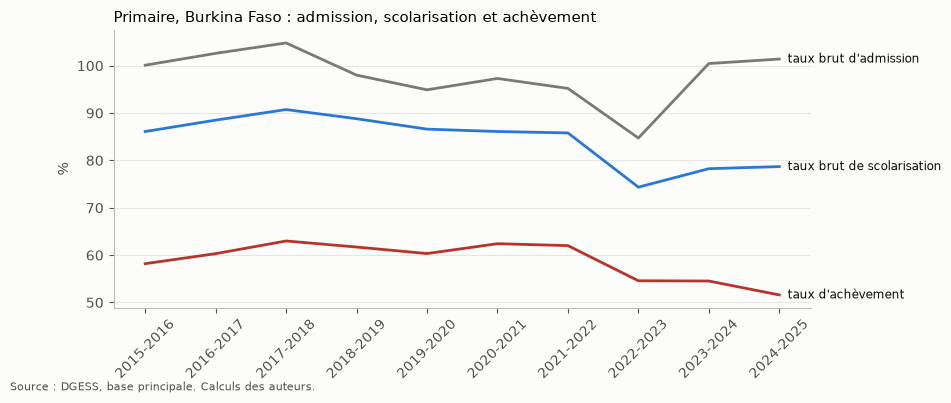

In [9]:
serie = resultat["serie_nationale_annee"].set_index("annee_scolaire")
fig, ax = plt.subplots(figsize=(9, 3.6))
for colonne, couleur, nom in [("tbs", "#2a78d6", "taux brut de scolarisation"), ("taux_achevement", "#b8342a", "taux d'achèvement"),
                              ("tba", "#7a7974", "taux brut d'admission")]:
    ax.plot(serie.index, serie[colonne], color=couleur, linewidth=2)
    ax.annotate(nom, (serie.index[-1], serie[colonne].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                fontsize=8.5, color="#0b0b0b", va="center")
ax.set_ylabel("%"); ax.grid(axis="y", color="#e2e1dc", linewidth=0.6); ax.tick_params(axis="x", rotation=45)
ax.set_title("Primaire, Burkina Faso : admission, scolarisation et achèvement", loc="left", fontsize=11)
fig.text(0.01, -0.12, "Source : DGESS, base principale. Calculs des auteurs.", fontsize=8, color="#52514e")
plt.show()

## 4. Les ruptures de scolarisation

Elles signalent les provinces où les écoles ont fermé ou rouvert en masse. Elles ne sont pas un taux d'abandon, mais une alerte d'un autre type, traitée par un modèle distinct.

In [10]:
ruptures = panel[panel["statut_cible"] == "rupture de scolarisation"]
ruptures[["province_ancienne_nom", "annee_scolaire", "effectif", "effectif_suivant", "evolution_effectifs_suivante"]].sort_values(
    "evolution_effectifs_suivante").head(15)

,province_ancienne_nom,annee_scolaire,effectif,effectif_suivant,evolution_effectifs_suivante
221,Komandjari,2021-2022,3845.0,0.0,-1.0000
23,Banwa,2021-2022,47993.0,295.0,-0.9939
274,Loroum,2020-2021,21968.0,527.0,-0.9760
50,Nayala,2021-2022,32136.0,5002.0,-0.8443
352,Soum,2017-2018,55224.0,13926.0,-0.7478
58,Sourou,2020-2021,29316.0,9690.0,-0.6695
203,Gnagna,2021-2022,42247.0,15638.0,-0.6298
363,Yagha,2019-2020,5935.0,2373.0,-0.6002
334,Oudalan,2017-2018,23567.0,11796.0,-0.4995
122,Namentenga,2021-2022,52762.0,27322.0,-0.4822


## 5. La table mensuelle

In [11]:
mensuel = resultat["panel_mensuel_province"]
mensuel.groupby("mois")["deplaces"].sum().iloc[[0, 6, 12, 24, 36, -1]].astype(int)

mois
2019-01      81964
2019-07     237769
2020-02     779741
2021-04    1218754
2022-04    1520012
2023-03    2062534
Name: deplaces, dtype: int64

## 6. Schéma des relations entre tables

In [12]:
resultat["schema_relations"]

,table,cle,table_liee,cle_liee,cardinalite
0,panel_province_annee,province_ancienne_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un
1,panel_province_annee,region_ancienne_pcode,region_ancienne,region_ancienne_pcode,plusieurs à un
2,panel_mensuel_province,province_ancienne_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un
3,province,province_ancienne_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un (2 provinces scindées)
4,commune,province_ancienne_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un
5,commune,province_pcode,province,province_pcode,plusieurs à un
6,fait_effectifs_retenus,entite_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un
7,fait_offre_province,entite_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un
8,fait_flux_publie,entite_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un
9,fait_esu_province,province_ancienne_pcode,province_ancienne,province_ancienne_pcode,plusieurs à un


## 7. Dépôt au format du challenge

In [13]:
depot = exporter_transformation(version=1)
depot[["fichier_depose", "role"]]

,fichier_depose,role
0,EXX_03-transformation_D1_engineer_table-analyse-risque-decrochage-province-annee_v1.csv,engineer
1,EXX_03-transformation_D1_engineer_deplaces-ecoles-fermees-province-mensuel_v1.csv,engineer
2,EXX_03-transformation_D1_engineer_indicateurs-regionaux-base-principale-2016-2025_v1.csv,engineer
3,EXX_03-transformation_D1_engineer_serie-nationale-statut-milieu-classe-2016-2025_v1.csv,engineer
4,EXX_03-transformation_D1_architect_dictionnaire-variables-table-analyse_v1.csv,architect
5,EXX_03-transformation_D1_architect_dictionnaire-variables-region-nation_v1.csv,architect
6,EXX_03-transformation_D1_architect_schema-relations-entre-tables_v1.csv,architect
7,EXX_03-transformation_D1_architect_metadonnees-variables-bases-modele_v1.csv,architect
8,EXX_03-transformation_D1_architect_metadonnees-tables-bases-modele_v1.csv,architect
9,EXX_03-transformation_D1_architect_metadonnees-datapackage-frictionless_v1.json,architect


## Suite

L'étape 04 entraîne, sur les lignes « abandon observé », un modèle de l'abandon de l'année suivante, toujours comparé à la référence naïve (l'abandon de l'année précédente) et validé dans le temps. Un second modèle estime le risque de rupture de scolarisation à partir des lignes « rupture ».